## Data Preprocessing

For Data Preprocessing, we use Scikit-Learn library.<br>
Installation command - **pip install scikit-learn**

In [1071]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1072]:
df = pd.read_csv('/Users/venu/programming/MLProject-1/src/ml_trainer/L4 - 8th oct Data Preprocessing (Practical)/loan.csv')

In [1073]:
df.head()

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36 months,11.44,329.48,Marketing,10+ years,RENT,117000.0,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,Credit analyst,4 years,MORTGAGE,65000.0,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,Statistician,< 1 year,RENT,43057.0,Source Verified,Jan-2015,Fully Paid,credit_card,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,Client Advocate,6 years,RENT,54000.0,Not Verified,Nov-2014,Fully Paid,credit_card,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,Destiny Management Inc.,9 years,MORTGAGE,55000.0,Verified,Apr-2013,Charged Off,credit_card,"679 Luna Roads\r\nGreggshire, VA 11650"


Taking starting 50000 rows for preprocessing

In [1074]:
df = df.iloc[:50000,:]

In [1075]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_amnt            50000 non-null  float64
 1   term                 50000 non-null  str    
 2   int_rate             50000 non-null  float64
 3   installment          50000 non-null  float64
 4   emp_title            47144 non-null  str    
 5   emp_length           47708 non-null  str    
 6   home_ownership       50000 non-null  str    
 7   annual_inc           50000 non-null  float64
 8   verification_status  50000 non-null  str    
 9   issue_d              50000 non-null  str    
 10  loan_status          50000 non-null  str    
 11  purpose              50000 non-null  str    
 12  address              50000 non-null  str    
dtypes: float64(4), str(9)
memory usage: 5.0 MB


In [1076]:
df.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'purpose', 'address'],
      dtype='str')

### 1. Checking For Duplicates

In [1077]:
df.duplicated().sum()

np.int64(0)

### 2. Missing Values Detection

In [1078]:
df.isna().sum()

loan_amnt                 0
term                      0
int_rate                  0
installment               0
emp_title              2856
emp_length             2292
home_ownership            0
annual_inc                0
verification_status       0
issue_d                   0
loan_status               0
purpose                   0
address                   0
dtype: int64

### 3. Outlier Detection

- Outliers can be detected only in numerical columns
- It is not possible to have outliers in categorical columns

In [1079]:
df_numeric = df.select_dtypes(include=['float','int'])
df_numeric.head(3)

,loan_amnt,int_rate,installment,annual_inc
0,10000.0,11.44,329.48,117000.0
1,8000.0,11.99,265.68,65000.0
2,15600.0,10.49,506.97,43057.0


In [1080]:
df_categorical = df.select_dtypes(include = 'object')
df_categorical.head(3)

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2577594014.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_categorical = df.select_dtypes(include = 'object')


,term,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,purpose,address
0,36 months,Marketing,10+ years,RENT,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,36 months,Credit analyst,4 years,MORTGAGE,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,36 months,Statistician,< 1 year,RENT,Source Verified,Jan-2015,Fully Paid,credit_card,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"


Outliers can be detected using two different plots
1.  Box Plot
2.  Density Plot

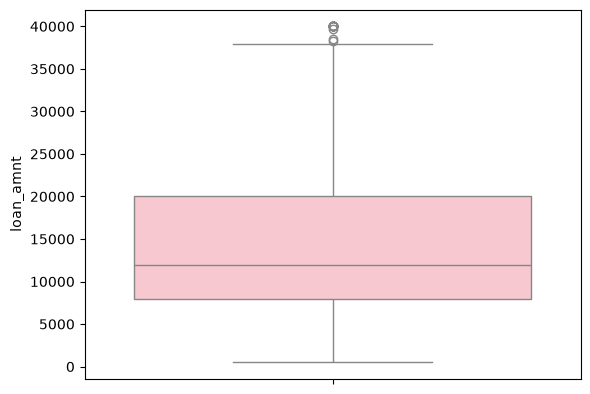

In [1081]:
# Loan Amount Column -
sns.boxplot(y=df['loan_amnt'], color='pink')
plt.show()

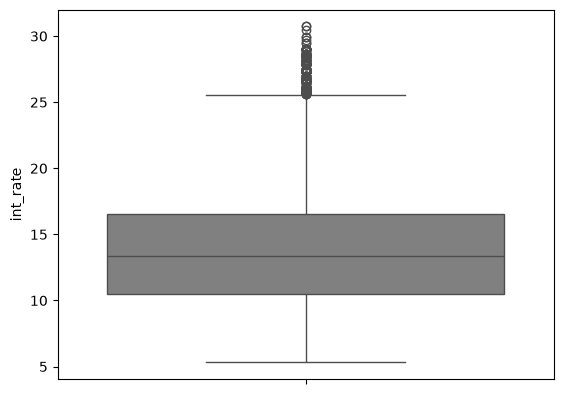

In [1082]:
# Interest Rate Column - 
sns.boxplot(y=df['int_rate'], color='grey')
plt.show()

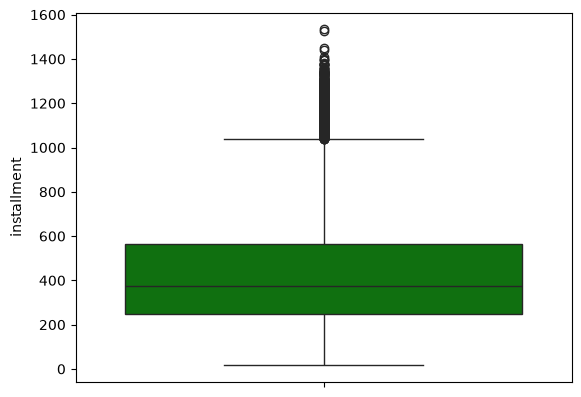

In [1083]:
# Installment Column -
sns.boxplot(y=df['installment'], color='green')
plt.show()

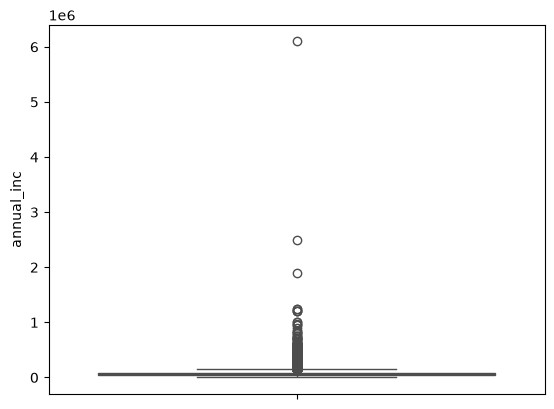

In [1084]:
# Annual Income Column -
sns.boxplot(y=df['annual_inc'], color='blue')
plt.show()

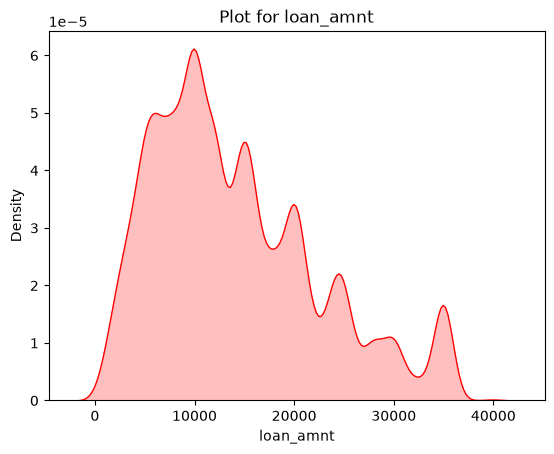

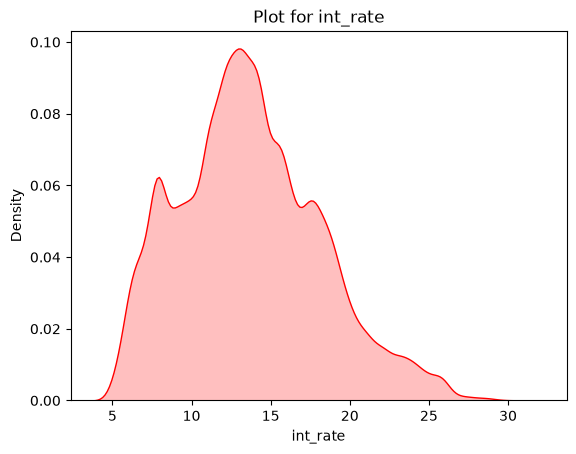

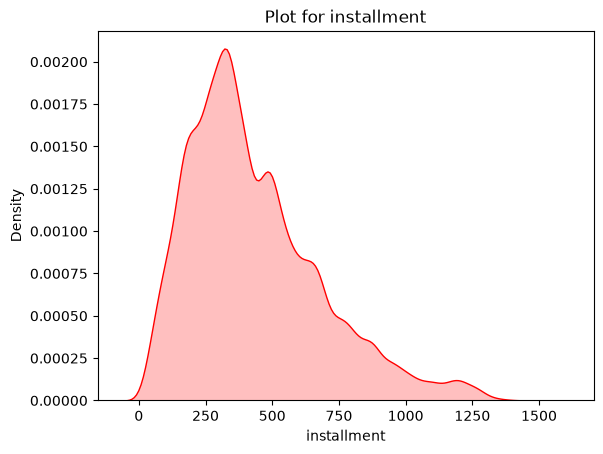

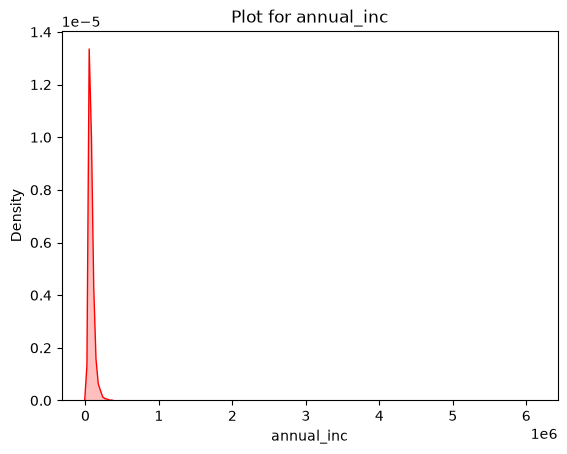

In [1085]:
for col in df_numeric.columns:
    sns.kdeplot(x=df[col], fill=True, color='red')
    plt.title(f'Plot for {col}')
    plt.show()

#### Displaying the statistical summary of the numeric columns

In [1086]:
df_numeric.describe()

,loan_amnt,int_rate,installment,annual_inc
count,50000.000000,50000.000000,50000.000000,5.000000e+04
mean,14105.965000,13.657471,431.434680,7.417736e+04
std,8361.115955,4.461604,250.253421,5.767275e+04
min,500.000000,5.320000,16.310000,2.500000e+03
25%,8000.000000,10.490000,250.367500,4.500000e+04
50%,12000.000000,13.330000,375.490000,6.350000e+04
75%,20000.000000,16.550000,566.225000,9.000000e+04
max,40000.000000,30.740000,1533.810000,6.100000e+06


#### Observation:
- A big difference in the maximum value and 75th percentile is seen inside the Installment & Annual Income Column
- Hence we can treat its outliers with the help of IQR method.
- IQR gives us the row numbers having outliers.

### 4. Data Distributions

**A. Categorical Columns**

In [1087]:
df_categorical.columns

Index(['term', 'emp_title', 'emp_length', 'home_ownership',
       'verification_status', 'issue_d', 'loan_status', 'purpose', 'address'],
      dtype='str')

In [1088]:
for col in df_categorical.columns:
    print(f'{col} - {df[col].nunique()}')

term - 2
emp_title - 28999
emp_length - 11
home_ownership - 6
verification_status - 3
issue_d - 115
loan_status - 2
purpose - 14
address - 49954


Checking the distribution of some selected columns having less number of unique values

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


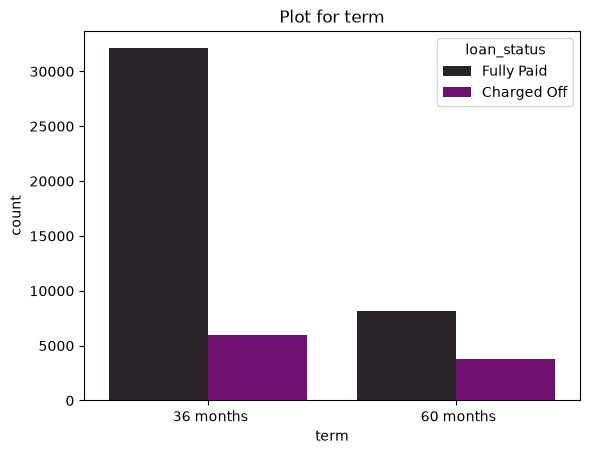

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


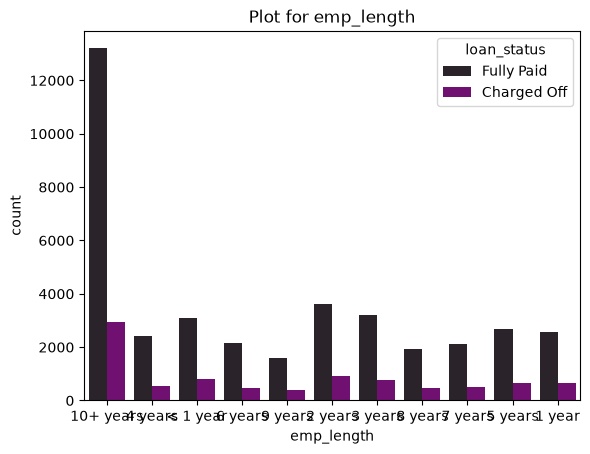

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


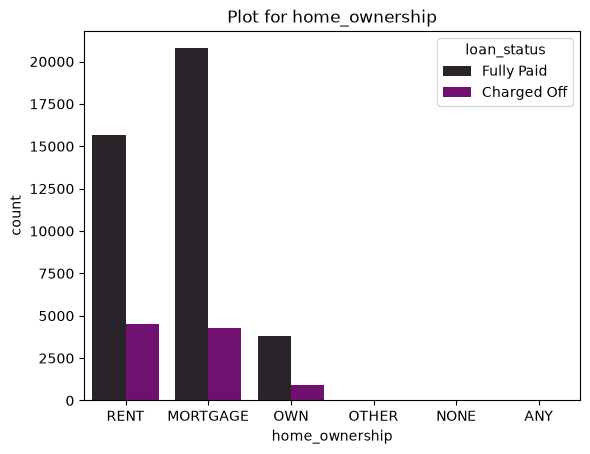

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


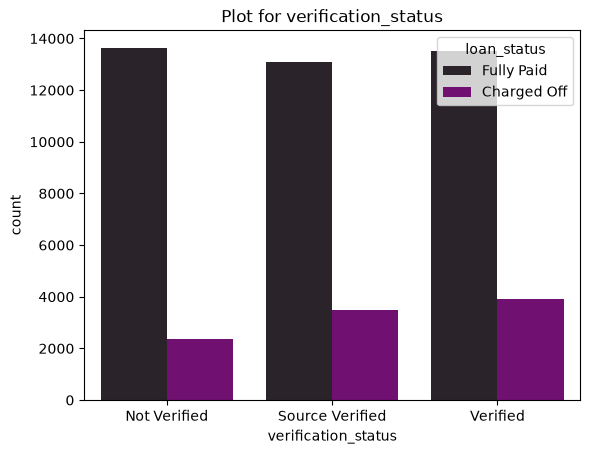

In [1089]:
for c in ['term', 'emp_length', 'home_ownership', 'verification_status']:
    sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')
    plt.title(f'Plot for {c}')
    plt.show()

**B. Numeric Columns**

In [1090]:
df_numeric.columns

Index(['loan_amnt', 'int_rate', 'installment', 'annual_inc'], dtype='str')

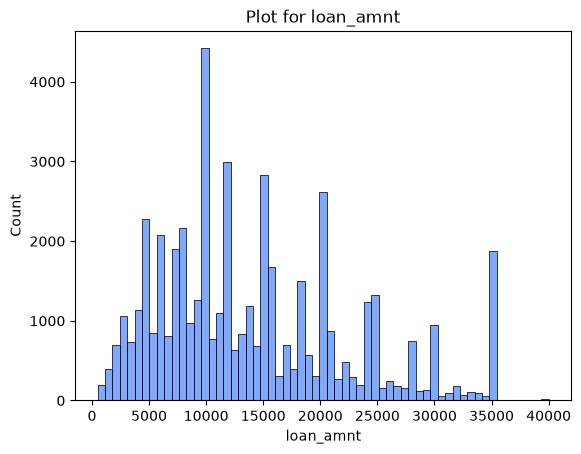

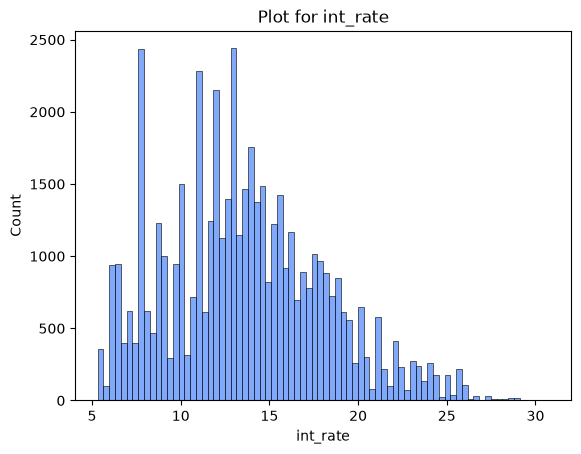

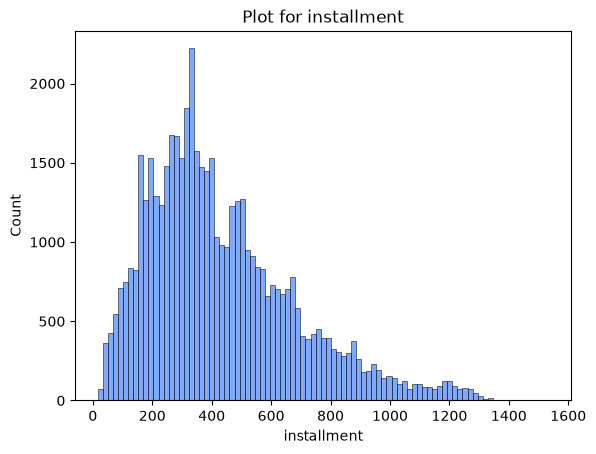

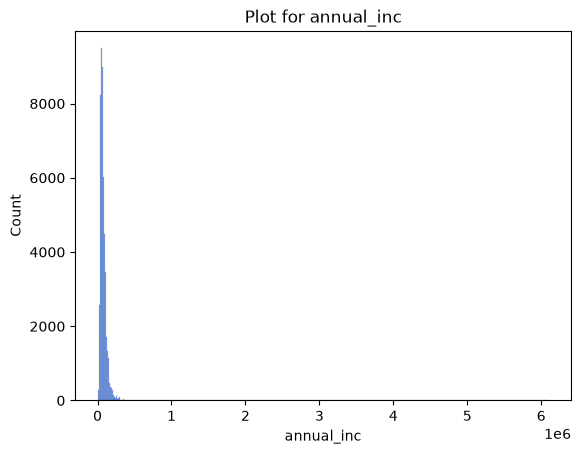

In [1091]:
for c in df_numeric.columns:
    sns.histplot(x=c, data=df_numeric)
    plt.title(f'Plot for {c}')
    plt.show()

### 5. Checking the association between all the columns using Statistical Tests

In [1092]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36 months,11.44,329.48,Marketing,10+ years,RENT,117000.0,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,Credit analyst,4 years,MORTGAGE,65000.0,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"


**- loan_status is the target column, hence checking its association with all the other columns
- loan_status is the categorical column**

In [1093]:
df['loan_status'].value_counts()

loan_status
Fully Paid     40242
Charged Off     9758
Name: count, dtype: int64

#### Categorical vs. Categorical - Chi-square Test
- H0 : No association between the two variables
- Ha : Association between the two variables

In [1094]:
from scipy.stats import chi2_contingency

**a. term vs. loan_status**

In [1095]:
table = pd.crosstab(df['term'], df['loan_status'])
print(table)

'''
pandas.crosstab() function in Python
pandas.crosstab() function in Python is used to compute a cross-tabulation (contingency table) of two or more categorical variables. By default, computes a frequency table of the factors unless an array of values and an aggregation function are passed. It also supports aggregation when additional data and a custom function are provided. This function is ideal for summarizing relationships between categories and analyzing patterns in datasets efficiently.
import pandas as pd

a = {
    'Gender': ['Male', 'Female', 'Female', 'Male', 'Female', 'Male'],
    'Product': ['A', 'B', 'A', 'A', 'C', 'B']
}

df = pd.DataFrame(a)

# Generate crosstab
res = pd.crosstab(df['Gender'], df['Product'])

'''

loan_status  Charged Off  Fully Paid
term                                
36 months           5999       32086
60 months           3759        8156


"\npandas.crosstab() function in Python\npandas.crosstab() function in Python is used to compute a cross-tabulation (contingency table) of two or more categorical variables. By default, computes a frequency table of the factors unless an array of values and an aggregation function are passed. It also supports aggregation when additional data and a custom function are provided. This function is ideal for summarizing relationships between categories and analyzing patterns in datasets efficiently.\nimport pandas as pd\n\na = {\n    'Gender': ['Male', 'Female', 'Female', 'Male', 'Female', 'Male'],\n    'Product': ['A', 'B', 'A', 'A', 'C', 'B']\n}\n\ndf = pd.DataFrame(a)\n\n# Generate crosstab\nres = pd.crosstab(df['Gender'], df['Product'])\n\n"


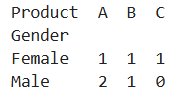

In [1096]:
chi2, p_val, dof, expected = chi2_contingency(table)

In [1097]:
print("p-value:", p_val)

p-value: 0.0


In [1098]:
alpha = 0.05

if p_val < alpha:
    print("Reject H0 and Accept Ha. The variables are significantly dependent (associated).")
else:
    print("Accept H0 and Reject Ha. The variables are independent (no significant association).")

Reject H0 and Accept Ha. The variables are significantly dependent (associated).


As we have to find the association between multiple columns, hence combining all the steps into a single function

In [1099]:
def association_function(col):
    table = pd.crosstab(df[col], df['loan_status'])
    chi2, p_val, dof, expected = chi2_contingency(table)

    alpha = 0.05
    if p_val < alpha:
        return p_val, "Reject H0 and Accept Ha"
    else:
        return p_val, "Accept H0 and Reject Ha"

##check for all categorical columns..


**b. emp_title vs. loan_status**

In [1100]:
p_val, result = association_function('emp_title')
print("P-value:", p_val)
print("Test Result:",result)

## here p value os 0.719 which is more than alpha value of 0.05.
# ##we can say, there  is no match ore dependency between loan status and emp title.

P-value: 0.7194307632168884
Test Result: Accept H0 and Reject Ha


**c. emp_length vs. loan_status**

In [1101]:
p_val, result = association_function('emp_length')
print("P-value:", p_val)
print("Test Result:",result)

# pvalue = 0.009 less than alpha. so there is a strong relation

P-value: 0.009633461164498681
Test Result: Reject H0 and Accept Ha


**d. home_ownership vs. loan_status**

In [1102]:
p_val, result = association_function('home_ownership')
print("P-value:", p_val)
print("Test Result:",result)

##P-value: -1.28 10 power 42> alpha so there is a relationship.

P-value: 1.2811973157811789e-42
Test Result: Reject H0 and Accept Ha


- The tests shows an association between the target (loan_status) column and other categorical variables.
- To find the strength of the association, we can use cramer's V rule (optional)

#### Categorical vs. Numerical - ANOVA
- H0 : All groups means are equal (One column does not affect another column, hence no significance association)
- Ha : At least one mean is different (One column affects another column, hence there is a significance association)


In [1103]:
from scipy.stats import f_oneway

In [1104]:
def association_function1(col):
    groups = [group[col].values for name, group in df.groupby('loan_status')]
    print(groups)
    print(len(groups))

association_function1('int_rate')

df.head(5)


[array([17.27, 11.36, 13.35, ..., 21.18, 11.83, 18.25], shape=(9758,)), array([11.44, 11.99, 10.49, ..., 15.88, 16.55, 12.29], shape=(40242,))]
2


,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36 months,11.44,329.48,Marketing,10+ years,RENT,117000.0,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,Credit analyst,4 years,MORTGAGE,65000.0,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,Statistician,< 1 year,RENT,43057.0,Source Verified,Jan-2015,Fully Paid,credit_card,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,Client Advocate,6 years,RENT,54000.0,Not Verified,Nov-2014,Fully Paid,credit_card,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,Destiny Management Inc.,9 years,MORTGAGE,55000.0,Verified,Apr-2013,Charged Off,credit_card,"679 Luna Roads\r\nGreggshire, VA 11650"


In [1105]:
groups = [group['loan_amnt'].values for name, group in df.groupby('loan_status')]
groups

[array([24375.,  6000.,  8400., ...,  7200.,  5000., 24625.], shape=(9758,)),
 array([10000.,  8000., 15600., ..., 23500., 30500., 21000.],
       shape=(40242,))]

In [1106]:
def association_function(col):
    groups = [group[col].values for name, group in df.groupby('loan_status')]
    f_stat, p_val = f_oneway(*groups)

    ##above lines explanation is there in understanding_concept.ipynb file
    
    alpha = 0.05
    if p_val < alpha:
        return p_val, f"Reject H0 - Loan status has a significant effect on {col}"
    else:
        return p_val, f"Accept H0 - No significant effect of loan status on {col}"

**a. laon_amnt vs. loan_status**

In [1107]:
p_val, result = association_function('loan_amnt')
print("P-value:", p_val)
print("Test Result:",result)

#where "e" stands for "times 10 to the power of").

P-value: 1.6000360117135658e-40
Test Result: Reject H0 - Loan status has a significant effect on loan_amnt


**b. int_rate vs. loan_status**

In [1108]:
p_val, result = association_function('int_rate')
print("P-value:", p_val)
print("Test Result:",result)

P-value: 0.0
Test Result: Reject H0 - Loan status has a significant effect on int_rate


**c. installment vs. loan_status**

In [1109]:
p_val, result = association_function('installment')
print("P-value:", p_val)
print("Test Result:",result)

P-value: 9.209373664974711e-20
Test Result: Reject H0 - Loan status has a significant effect on installment


**d. annual_inc vs. loan_status**

In [1110]:
p_val, result = association_function('annual_inc')
print("P-value:", p_val)
print("Test Result:",result)

P-value: 1.9870730873178603e-36
Test Result: Reject H0 - Loan status has a significant effect on annual_inc


- The tests shows an association between the target (loan_status) column and other numerical variables.
- To find the strength of the association, we can use eta-squared method (optional)

#### Observation:
1. Almost all the columns shows an association with the loan_status column (even if it is small), therefore, we consider the effect and will not drop any column.

### 6. Encoding the Categorical Columns

In [1111]:
df_categorical.head()

,term,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,purpose,address
0,36 months,Marketing,10+ years,RENT,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,36 months,Credit analyst,4 years,MORTGAGE,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,36 months,Statistician,< 1 year,RENT,Source Verified,Jan-2015,Fully Paid,credit_card,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,36 months,Client Advocate,6 years,RENT,Not Verified,Nov-2014,Fully Paid,credit_card,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,60 months,Destiny Management Inc.,9 years,MORTGAGE,Verified,Apr-2013,Charged Off,credit_card,"679 Luna Roads\r\nGreggshire, VA 11650"


**Checking for unique values in all the categorical columns**

In [1112]:
for c in df_categorical.columns:
    print(f'{c} - {df_categorical[c].nunique()}')

'''
A. One-hot encoding
Use this when categories have no natural order and the number of categories is relatively small.

ncoding technique	            Columns	                                        Why it may be used
Target Encoding	emp_title,      home_ownership,                                 purpose	Replaces categories with a statistic calculated from the target variable
One-Hot Encoding	            verification_status	                            Creates separate binary columns for a small number of categories
Custom Encoding	                term, loan_status, emp_length, issue_d, address	Applies a transformation designed around the meaning and format of each column

'''

term - 2
emp_title - 28999
emp_length - 11
home_ownership - 6
verification_status - 3
issue_d - 115
loan_status - 2
purpose - 14
address - 49954


'\nA. One-hot encoding\nUse this when categories have no natural order and the number of categories is relatively small.\n\nncoding technique\t            Columns\t                                        Why it may be used\nTarget Encoding\temp_title,      home_ownership,                                 purpose\tReplaces categories with a statistic calculated from the target variable\nOne-Hot Encoding\t            verification_status\t                            Creates separate binary columns for a small number of categories\nCustom Encoding\t                term, loan_status, emp_length, issue_d, address\tApplies a transformation designed around the meaning and format of each column\n\n'

#### Observation:
- Target Encoding: emp_title, home_ownership, purpose  -- unique values are more and there is no order
- One Hot Encoding: verification_status  -- when unique values are few
- Custom Encoding: term, loan_status, emp_length, issue_d, address      -- apply our logic.

### why different encoding techniques:

### Let's apply Custom Encoding

**a) term column**

In [1113]:
df['term'].value_counts()

term
36 months    38085
60 months    11915
Name: count, dtype: int64

In [1114]:
df['term'] = df['term'].apply(lambda x:int(x.split()[0]))

In [1115]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36,11.44,329.48,Marketing,10+ years,RENT,117000.0,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36,11.99,265.68,Credit analyst,4 years,MORTGAGE,65000.0,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"


**b) loan_status column**

In [1116]:
df['loan_status'].value_counts()

loan_status
Fully Paid     40242
Charged Off     9758
Name: count, dtype: int64

In [1117]:
df['loan_status'] = df['loan_status'].apply(lambda n: 1 if n == 'Fully Paid' else 0)

In [1118]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36,11.44,329.48,Marketing,10+ years,RENT,117000.0,Not Verified,Jan-2015,1,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36,11.99,265.68,Credit analyst,4 years,MORTGAGE,65000.0,Not Verified,Jan-2015,1,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"


**c) emp_length column**

In [1119]:
df['emp_length'].value_counts()

emp_length
10+ years    16139
2 years       4524
3 years       3988
< 1 year      3899
5 years       3334
1 year        3216
4 years       2957
6 years       2657
7 years       2608
8 years       2390
9 years       1996
Name: count, dtype: int64

In [1120]:
df['emp_length'].isna().sum()

np.int64(2292)

Since there are missing values in the column and as this is a categorical column, hence we fill the values with the mode

In [1121]:
mode = df['emp_length'].mode().values[0]
mode

'10+ years'

In [1122]:
df['emp_length']  = df['emp_length'].fillna(mode)

In [1123]:
df['emp_length'].isna().sum()

np.int64(0)

In [1124]:
df['emp_length'].isna().sum()

np.int64(0)

In [1125]:
def emp_length_encoding(n):
    if n == '10+ years':
        return 10
    elif n == '< 1 year':
        return 0
    else:
        return int(n.split()[0])    

In [1126]:
df['emp_length'] = df['emp_length'].apply(emp_length_encoding)


In [1127]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,Not Verified,Jan-2015,1,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,Not Verified,Jan-2015,1,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"


**d) issue_d column**

In [1128]:
df_categorical['issue_d'].value_counts()

issue_d
Oct-2014    1897
Jul-2014    1638
Jan-2015    1481
Dec-2013    1432
Nov-2013    1330
            ... 
Sep-2007       2
Nov-2007       2
Sep-2008       1
Jun-2007       1
Jul-2007       1
Name: count, Length: 115, dtype: int64

In [1129]:
df['issue_d'] = df['issue_d'].apply(lambda n: int(n.split('-')[1]))

In [1130]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,Not Verified,2015,1,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,Not Verified,2015,1,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"


**e) address column**

In [1131]:
df['address'].value_counts()

address
USCGC Miller\r\nFPO AE 22690                                  3
USNV Brown\r\nFPO AA 70466                                    3
USS Brown\r\nFPO AE 30723                                     3
USNS Shepherd\r\nFPO AE 48052                                 2
USCGC Smith\r\nFPO AP 70466                                   2
                                                             ..
690 Joseph Locks Suite 273\r\nTeresashire, MN 11650           1
778 Andrew Dale Suite 736\r\nPort Christinemouth, NC 22690    1
731 Stephen Lake Apt. 388\r\nWebbfort, SC 30723               1
09418 Anderson Greens\r\nSouth Stacey, DE 00813               1
50737 Joseph Groves\r\nLake Joseph, ME 48052                  1
Name: count, Length: 49954, dtype: int64

In [1132]:
df['pincode'] = df['address'].apply(lambda x:int(x.split()[-1]))

In [1133]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address,pincode
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,Not Verified,2015,1,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690",22690
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,Not Verified,2015,1,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113",5113


As a new pincode column is created, hence we will remove the address column

In [1134]:
df.drop('address', axis=1, inplace=True)

In [1135]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,pincode
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,Not Verified,2015,1,vacation,22690
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,Not Verified,2015,1,debt_consolidation,5113


### Applying One-Hot Encoding

In [1136]:
from sklearn.preprocessing import OneHotEncoder



**verification_status column**

***One hot encoder expects a 2 d array**

In [1137]:
df['verification_status'].value_counts()

verification_status
Verified           17410
Source Verified    16591
Not Verified       15999
Name: count, dtype: int64

In [1138]:
type(df['verification_status'])

pandas.Series

***One Hot Encoder expects a 2D array***


In [1139]:
print(type(df['verification_status'].values))
df['verification_status'].values

## .values returns a string array but we need 2D for onehot encoding.. so reshape it for 2D

<class 'pandas.arrays.StringArray'>


<StringArray>
[   'Not Verified',    'Not Verified', 'Source Verified',    'Not Verified',
        'Verified',        'Verified', 'Source Verified',    'Not Verified',
        'Verified',        'Verified',
 ...
        'Verified',    'Not Verified',    'Not Verified',        'Verified',
    'Not Verified', 'Source Verified',        'Verified',        'Verified',
 'Source Verified', 'Source Verified']
Length: 50000, dtype: str

In [1140]:
reshaped_data = df['verification_status'].values.reshape(-1,1)
reshaped_data

print(f'printing new share: {reshaped_data.shape}')

'''
df['verification_status'].values.reshape(-1, 1):
It takes a Pandas column and converts it into a 2D NumPy array with one column.

converts a Pandas column into a 2D array with one column, which is useful because many Scikit-learn functions expect 2D input data.
Index	verification_status
0	    Verified
1	    Not Verified
2	    Source Verified


df['verification_status'].values
This extracts the column values into a NumPy array.

array(['Verified', 'Not Verified',
       'Source Verified', 'Verified'])

       Its shape is: (3,)
now we need to add 4 columns with these array vlaues and delete the main verification status column. for this we are using onehotencoder here.
if a row has verified then array will = [1,0,0] like this for others.
'''

printing new share: (50000, 1)


"\ndf['verification_status'].values.reshape(-1, 1):\nIt takes a Pandas column and converts it into a 2D NumPy array with one column.\n\nconverts a Pandas column into a 2D array with one column, which is useful because many Scikit-learn functions expect 2D input data.\nIndex\tverification_status\n0\t    Verified\n1\t    Not Verified\n2\t    Source Verified\n\n\ndf['verification_status'].values\nThis extracts the column values into a NumPy array.\n\narray(['Verified', 'Not Verified',\n       'Source Verified', 'Verified'])\n\n       Its shape is: (3,)\nnow we need to add 4 columns with these array vlaues and delete the main verification status column. for this we are using onehotencoder here.\nif a row has verified then array will = [1,0,0] like this for others.\n"

In [1141]:
encoder = OneHotEncoder()

In [1142]:
verification_encoded_data = encoder.fit_transform(reshaped_data)
verification_encoded_data

'''
This code is used to convert categorical text values into numerical values using an encoder.
1. What does fit_transform() do?
fit_transform() performs two operations:
- fit(): Learns the unique categories present in your data.
- transform(): Converts those categories into numerical values.

Step 1: Input data
reshaped_data
Text categories in a 2D array

Step 2: encoder.fit()
Learns the unique categories and their mappings

Step 3: encoder.transform()
Replaces text categories with numerical values.

Important: Ordinal encoding assigns numbers to categories, but those numbers do not necessarily represent a meaningful ranking. If you are encoding categories such as loan verification status, the numbers are labels, not scores.

'''

'\nThis code is used to convert categorical text values into numerical values using an encoder.\n1. What does fit_transform() do?\nfit_transform() performs two operations:\n- fit(): Learns the unique categories present in your data.\n- transform(): Converts those categories into numerical values.\n\nStep 1: Input data\nreshaped_data\nText categories in a 2D array\n\nStep 2: encoder.fit()\nLearns the unique categories and their mappings\n\nStep 3: encoder.transform()\nReplaces text categories with numerical values.\n\nImportant: Ordinal encoding assigns numbers to categories, but those numbers do not necessarily represent a meaningful ranking. If you are encoding categories such as loan verification status, the numbers are labels, not scores.\n\n'

***sparse matrix - when number of zeros are more***


In [1143]:
verification_encoded_data.toarray()

### to view what is stored.

array([[1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       ...,
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 1., 0.]], shape=(50000, 3))

In [1144]:
encoder.categories_[0]

##encoder.categories_[0] is used to display the unique categories that the encoder learned from the first column of your data.
##rep the order of options

array(['Not Verified', 'Source Verified', 'Verified'], dtype=object)

In [1145]:
df[encoder.categories_[0]] = verification_encoded_data.toarray()

##Purpose: This code is intended to create new columns in your DataFrame using encoded values. However, this works as expected only if encoder is a OneHotEncoder and the number of output columns matches the category names.
#.toarray()	Converts a sparse matrix into a regular NumPy array

# df[...] = ...	Assigns the encoded values to DataFrame columns

'''
Python effectively performs these assignments:
- df['Not Verified'] receives the first column.
- df['Source Verified'] receives the second column.
- df['Verified'] receives the third column.

Each category gets its own column. A value of 1 indicates which category applies to that row, while the other categories receive 0.
'''


"\nPython effectively performs these assignments:\n- df['Not Verified'] receives the first column.\n- df['Source Verified'] receives the second column.\n- df['Verified'] receives the third column.\n\nEach category gets its own column. A value of 1 indicates which category applies to that row, while the other categories receive 0.\n"

In [1146]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,pincode,Not Verified,Source Verified,Verified
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,Not Verified,2015,1,vacation,22690,1.0,0.0,0.0
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,Not Verified,2015,1,debt_consolidation,5113,1.0,0.0,0.0


After applying One Hot Encoding, we can remove the verification status column

In [1147]:
df.drop('verification_status', axis=1, inplace=True)

###once we created 3 new columns, we don't need verification status column.

In [1148]:
df.head(2)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,loan_status,purpose,pincode,Not Verified,Source Verified,Verified
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,2015,1,vacation,22690,1.0,0.0,0.0
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,2015,1,debt_consolidation,5113,1.0,0.0,0.0


#### Now before applying the Target Encoding, we will split the dataset in order to avoid data leakage

### 7. Data Splitting

Dividing the data into input (X) and output (y)

In [1149]:
df.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'issue_d', 'loan_status',
       'purpose', 'pincode', 'Not Verified', 'Source Verified', 'Verified'],
      dtype='str')

In [1150]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

In [1151]:
X.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
0,10000.0,36,11.44,329.48,Marketing,10,RENT,117000.0,2015,vacation,22690,1.0,0.0,0.0
1,8000.0,36,11.99,265.68,Credit analyst,4,MORTGAGE,65000.0,2015,debt_consolidation,5113,1.0,0.0,0.0
2,15600.0,36,10.49,506.97,Statistician,0,RENT,43057.0,2015,credit_card,5113,0.0,1.0,0.0


In [1152]:
y.head(3)

0    1
1    1
2    1
Name: loan_status, dtype: int64

#### Use train_test_split to split the data into train and test sets
train_test_split - It splits the data by shuffling the rows. This is known as shuffled splitting.

In [1153]:
from sklearn.model_selection import train_test_split

In [1154]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [1155]:
X_train.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
20330,11700.0,60,23.43,332.73,Billing,4,MORTGAGE,32700.0,2014,debt_consolidation,70466,0.0,1.0,0.0
17532,9000.0,36,10.25,291.47,Loomis Group,3,RENT,55000.0,2010,debt_consolidation,29597,1.0,0.0,0.0
45819,26500.0,36,11.99,880.06,Attorney,10,MORTGAGE,112000.0,2013,debt_consolidation,70466,0.0,0.0,1.0


In [1156]:
y_train.head(3)

20330    0
17532    1
45819    1
Name: loan_status, dtype: int64

In [1157]:
X_test.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
11841,13650.0,60,18.30,348.86,James Hardie Building Products,10,MORTGAGE,57600.0,2010,debt_consolidation,22690,0.0,1.0,0.0
19602,8050.0,36,14.49,277.05,Web Media Manager,2,RENT,80000.0,2014,debt_consolidation,29597,0.0,1.0,0.0
45519,14000.0,36,15.61,489.51,Legal Secretary,10,RENT,70000.0,2014,medical,48052,0.0,0.0,1.0


In [1158]:
y_test.head(3)

11841    1
19602    1
45519    0
Name: loan_status, dtype: int64

Before applying target encoding, let us check for the missing values and treat them

In [1159]:
X_train.select_dtypes(include='object').isna().sum()

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2095398166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train.select_dtypes(include='object').isna().sum()


emp_title         2306
home_ownership       0
purpose              0
dtype: int64

In [1160]:
X_test.select_dtypes(include='object').isna().sum()

##we should not have na values.. so

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/2854464053.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_test.select_dtypes(include='object').isna().sum()


emp_title         550
home_ownership      0
purpose             0
dtype: int64

In [1161]:
X_train['emp_title'].value_counts()

emp_title
Manager                       457
Teacher                       453
Registered Nurse              190
Supervisor                    189
RN                            174
                             ... 
Ranch Manager  Foreman          1
ENG. TECH. 6 SUPERVISOR         1
couriernet inc                  1
ACME Adjusting Company LLC      1
cma                             1
Name: count, Length: 23828, dtype: int64

Therefore, filling the missing values by creating a new category 'unknown'

In [1162]:
X_train['emp_title'].fillna('unknown', inplace=True)
X_test['emp_title'].fillna('unknown', inplace=True)

/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/3966349709.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  X_train['emp_title'].fillna('unknown', inplace=True)
/var/folders/dh/h0_dxqhx1m56k9x13q2xmnhw0000gn/T/ipykernel_2682/3966349709.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or S

11841     James Hardie Building Products
19602                  Web Media Manager
45519                    Legal Secretary
25747                   Security Officer
42642                     ticket network
                      ...               
25091              Office Representative
27853    Sr Global Marketing Coordinator
47278                            analyst
37020     Hugh Chatham Memorial Hospital
2217                         Poway Honda
Name: emp_title, Length: 10000, dtype: str

In [1163]:
X_train['emp_title'].isna().sum()

np.int64(2306)

In [1164]:
X_test['emp_title'].isna().sum()

np.int64(550)

- As the missing values inside the emp_title are treated, hence, let us apply the target encoding.
- To apply Target Encoding, we have to install category_encoders library

Installation Command - **pip install category_encoders**

In [1165]:
from category_encoders import TargetEncoder

In [1166]:
encoder_object = TargetEncoder(cols=['emp_title', 'home_ownership', 'purpose'])

In [1167]:
X_train = encoder_object.fit_transform(X_train, y_train)

X_train.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
20330,11700.0,60,23.43,332.73,0.783527,4,0.829295,32700.0,2014,0.795551,70466,0.0,1.0,0.0
17532,9000.0,36,10.25,291.47,0.830262,3,0.776571,55000.0,2010,0.795551,29597,1.0,0.0,0.0
45819,26500.0,36,11.99,880.06,0.924287,10,0.829295,112000.0,2013,0.795551,70466,0.0,0.0,1.0


In [1168]:
'''
X_train contains the input features.

y_train contains the target values, such as loan_status.
TargetEncoder converts categorical values into numbers using information from y_train.
For example, it can encode Engineer based on the average target value for records where emp_title is Engineer.
If the target values for engineers are 0, 1, 1, the average is:

(0+1+1)/3= 0.667
So Engineer could be encoded as approximately 0.667.

'''

'\nX_train contains the input features.\n\ny_train contains the target values, such as loan_status.\nTargetEncoder converts categorical values into numbers using information from y_train.\nFor example, it can encode Engineer based on the average target value for records where emp_title is Engineer.\nIf the target values for engineers are 0, 1, 1, the average is:\n\n(0+1+1)/3= 0.667\nSo Engineer could be encoded as approximately 0.667.\n\n'

In [1169]:
X_train.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
20330,11700.0,60,23.43,332.73,0.783527,4,0.829295,32700.0,2014,0.795551,70466,0.0,1.0,0.0
17532,9000.0,36,10.25,291.47,0.830262,3,0.776571,55000.0,2010,0.795551,29597,1.0,0.0,0.0
45819,26500.0,36,11.99,880.06,0.924287,10,0.829295,112000.0,2013,0.795551,70466,0.0,0.0,1.0


In [1170]:
'''
first time you build the logic and then fit transform it
next time, just apply the logic so use transform only.. unless your logic is different.
apply the same logic to test data using the same logic so use transform.
'''

'\nfirst time you build the logic and then fit transform it\nnext time, just apply the logic so use transform only.. unless your logic is different.\napply the same logic to test data using the same logic so use transform.\n'

In [1171]:
X_test = encoder_object.transform(X_test, y_test)

In [1172]:
X_test.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
11841,13650.0,60,18.30,348.86,0.804875,10,0.829295,57600.0,2010,0.795551,22690,0.0,1.0,0.0
19602,8050.0,36,14.49,277.05,0.804875,2,0.776571,80000.0,2014,0.795551,29597,0.0,1.0,0.0
45519,14000.0,36,15.61,489.51,0.852437,10,0.776571,70000.0,2014,0.730769,48052,0.0,0.0,1.0


In [1173]:
X_train.dtypes

loan_amnt          float64
term                 int64
int_rate           float64
installment        float64
emp_title          float64
emp_length           int64
home_ownership     float64
annual_inc         float64
issue_d              int64
purpose            float64
pincode              int64
Not Verified       float64
Source Verified    float64
Verified           float64
dtype: object

In [1174]:
X_test.dtypes

loan_amnt          float64
term                 int64
int_rate           float64
installment        float64
emp_title          float64
emp_length           int64
home_ownership     float64
annual_inc         float64
issue_d              int64
purpose            float64
pincode              int64
Not Verified       float64
Source Verified    float64
Verified           float64
dtype: object

#### Therefore, the encoding of all the catgeorical columns is completed

### 8. Outlier Treatment

In [1175]:
df_numeric.head()

,loan_amnt,int_rate,installment,annual_inc
0,10000.0,11.44,329.48,117000.0
1,8000.0,11.99,265.68,65000.0
2,15600.0,10.49,506.97,43057.0
3,7200.0,6.49,220.65,54000.0
4,24375.0,17.27,609.33,55000.0


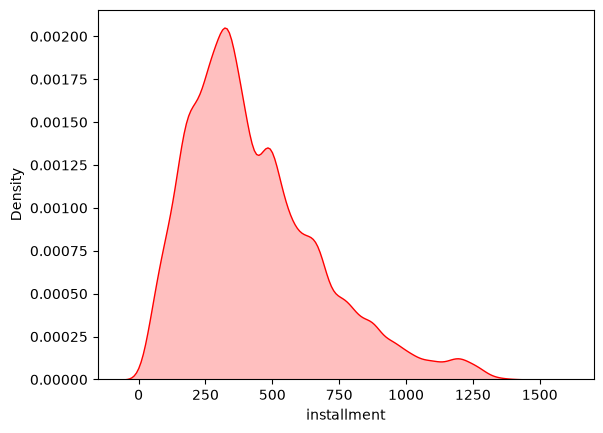

In [1176]:
sns.kdeplot(x = X_train['installment'], fill=True, color='red')
plt.show()

##before outlier treatment.

**As we have already checked above, let us treat the outliers of installment & annual income column using IQR method**

In [1177]:
Q1 = X_train['installment'].quantile(0.25)
Q3 = X_train['installment'].quantile(0.75)

IQR = Q3-Q1

upper_whisker = Q3 + (1.5*IQR)      ##upder bound
lower_whisker = Q1 - (1.5*IQR)      #lower bound

median = X_train['installment'].median()

outliers = X_train[(X_train['installment'] > upper_whisker) | (X_train['installment'] < lower_whisker)]['installment']

X_train.loc[outliers.index, 'installment'] = median

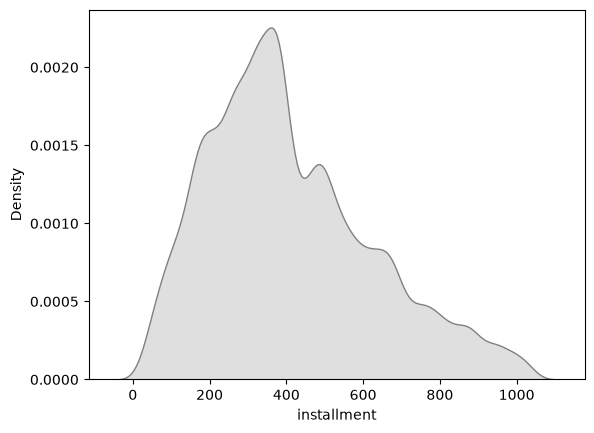

In [1178]:
sns.kdeplot(x = X_train['installment'], fill=True, color='grey')
plt.show()

##after treating the value is coming around 1000 - check x axis

Checking outliers in test data and treating them

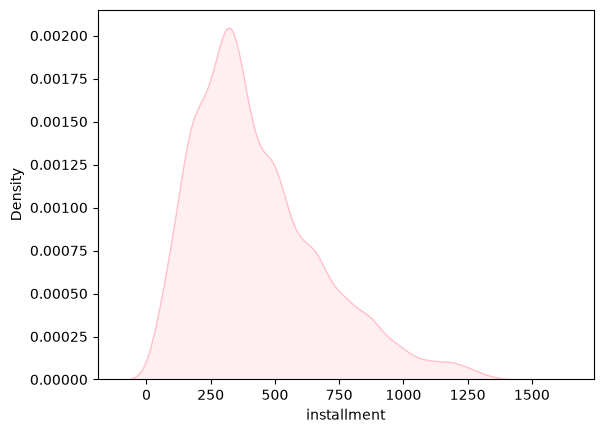

In [1179]:
sns.kdeplot(x = X_test['installment'], fill=True, color='pink')
plt.show()

In [1180]:
outliers = X_test[(X_test['installment'] > upper_whisker) | (X_test['installment'] < lower_whisker)]['installment']

X_test.loc[outliers.index, 'installment'] = median

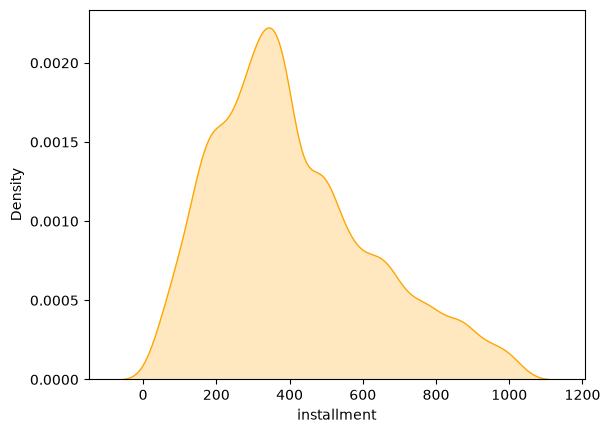

In [1181]:
sns.kdeplot(x = X_test['installment'], fill=True, color='orange')
plt.show()

**Task:** Treat the outliers for annual_inc column by applying log transformation.

### 9. Scaling the data

In [1182]:
X_train.head(3)

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
20330,11700.0,60,23.43,332.73,0.783527,4,0.829295,32700.0,2014,0.795551,70466,0.0,1.0,0.0
17532,9000.0,36,10.25,291.47,0.830262,3,0.776571,55000.0,2010,0.795551,29597,1.0,0.0,0.0
45819,26500.0,36,11.99,880.06,0.924287,10,0.829295,112000.0,2013,0.795551,70466,0.0,0.0,1.0


In [1183]:
from sklearn.preprocessing import StandardScaler

In [1184]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [1185]:
# optional
X_train[X_train.columns] = X_train_scaled

In [1186]:
X_train.head()

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
20330,-0.289421,1.784895,2.186938,-0.353844,-0.341766,-0.591957,0.974522,-0.708110,0.248554,-0.382057,1.422630,-0.685403,1.418227,-0.731060
17532,-0.612264,-0.560257,-0.762690,-0.545255,0.585707,-0.865555,-1.129456,-0.328334,-2.464181,-0.382057,-0.170758,1.458995,-0.705106,-0.731060
45819,1.480236,-0.560257,-0.373285,2.185299,2.451626,1.049632,0.974522,0.642395,-0.429630,-0.382057,1.422630,-0.685403,-0.705106,1.367877
34807,-0.313336,-0.560257,-1.351273,-0.234943,-1.996297,1.049632,0.974522,-0.692783,-1.107813,1.191014,-0.870470,1.458995,-0.705106,-0.731060
31888,-0.349207,-0.560257,-1.496740,-0.293814,0.585707,1.049632,0.974522,-0.481607,1.604922,-0.382057,-0.126858,1.458995,-0.705106,-0.731060


In [1187]:
X_test_scaled = scaler.transform(X_test)

In [1188]:
# optional
X_test[X_test.columns] = X_test_scaled

In [1189]:
X_test.head()

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,issue_d,purpose,pincode,Not Verified,Source Verified,Verified
11841,-0.056257,1.784895,1.038866,-0.279015,0.081893,1.049632,0.974522,-0.284055,-2.464181,-0.382057,-0.440046,-0.685403,1.418227,-0.731060
19602,-0.725857,-0.560257,0.186204,-0.612152,0.081893,-1.139154,-1.129456,0.097425,0.248554,-0.382057,-0.170758,-0.685403,1.418227,-0.731060
45519,-0.014407,-0.560257,0.436855,0.373481,1.025771,1.049632,-1.129456,-0.072879,0.248554,-3.047489,0.548760,-0.685403,-0.705106,1.367877
25747,0.105164,-0.560257,1.027676,0.627057,-0.462604,1.049632,-1.129456,-0.532698,0.248554,-0.382057,-1.292980,-0.685403,-0.705106,1.367877
42642,-0.681018,-0.560257,-0.471756,-0.607605,0.081893,-1.686350,0.974522,0.012273,-0.429630,0.748476,-0.170758,-0.685403,1.418227,-0.731060


## 10. Model Building

### **Machine Learning:**
1. Supervised Machine Learning - A type of algorithm that takes both input and output as data
2. Unsupervised Machine Learning - A type of algorithm that takes only input as data

##### Supervised ML: The one that deals with both input & output

There are two types of data:
1. Categorical
2. Numerical

Data ---> Divide Columns ---> 1. Features/Input
                              2. Target/Output

Target:
1. Numerical - ex: House Price, Car Price, Salary, Hotel Price, Student Performance, etc.
2. Categorical - ex: Loan Approval, Diabetes Prediction, Heart Disease Prediction, Obesity, Cancer, Fraud, etc.

Supervised Machine Learning ---> Algorithms ---> Look for Target<br>

If Target categorical ---> some algorithms --- classification-based algorithms<br>
If Target numerical ---> some algorithms --- regression-based algorithms

Types of Supervised Machine Learning Algorithms:
1. Linear Regression (numerical target)
2. Logistic Regression (categorical target)
3. K Nearest Neighbor (both)
4. Decision Trees (both)
5. Bagging/Random Forest (both)
6. Boosting (both)
7. Naive Bayes (categorical target)
8. SVM (categorical target)